**Punto 1**

In [137]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import random

n_centers = random.randint(1, 20)

blob_centers = []
while len(blob_centers) < n_centers:
    candidate = np.random.uniform(-25, 25, size=2)
    if all(np.linalg.norm(candidate - center) > 3 for center in blob_centers):
        blob_centers.append(candidate)

blob_centers = np.array(blob_centers)

blob_std = np.random.uniform(1, 2.5, size=n_centers)

puntos_por_centroide = [random.randint(50, 150) for _ in range(n_centers)]

X, y = make_blobs(n_samples=puntos_por_centroide, centers=blob_centers,
                  cluster_std=blob_std, random_state=42)

print(f"Se generaron {n_centers} centroides")
print("Coordenadas de los centroides iniciales/reales:")
print(blob_centers)

Se generaron 11 centroides
Coordenadas de los centroides iniciales/reales:
[[-11.12814536  10.93486172]
 [-22.12182555   1.05231593]
 [-17.18300373  16.64798484]
 [ -4.28564503   5.21540011]
 [  4.10934024 -19.78593562]
 [-19.99285247   3.57635136]
 [ -9.25095101 -19.42944202]
 [ -9.49986948 -15.46752271]
 [-23.01691597  -6.00826423]
 [  9.03714575 -19.33777504]
 [-21.58091177 -20.38879122]]


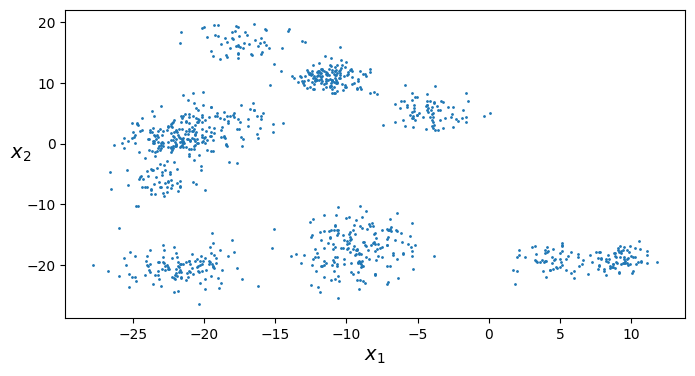

In [138]:
def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)

plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.show()

In [162]:
from sklearn.cluster import KMeans

k = n_centers

kmeans_iter1 = KMeans(n_clusters=k, init="k-means++", n_init=1, algorithm="lloyd", max_iter=1, random_state=1)
kmeans_iter2 = KMeans(n_clusters=k, init="k-means++", n_init=1, algorithm="lloyd", max_iter=2, random_state=1)
kmeans_iter3 = KMeans(n_clusters=k, init="k-means++", n_init=1, algorithm="lloyd", max_iter=5, random_state=1)

kmeans_iter1.fit(X)
kmeans_iter2.fit(X)
kmeans_iter3.fit(X)

kmeans_final = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
y_pred = kmeans_final.fit_predict(X)

print(f"RESULTADOS FINALES DE K-MEANS ({k} CLUSTERS)")
print("Ubicación final de los centroides:")
print(kmeans_final.cluster_centers_)

RESULTADOS FINALES DE K-MEANS (11 CLUSTERS)
Ubicación final de los centroides:
[[ -4.13167518   5.25678904]
 [ -9.92645203 -20.31296174]
 [  7.10360397 -19.15027832]
 [-23.06825905  -6.11687128]
 [-11.1663715   10.9381246 ]
 [-23.29420165 -20.78295132]
 [-22.11459318   0.67835765]
 [-17.36786899  16.81994027]
 [ -8.86447149 -15.25427852]
 [-19.89748714 -19.88200794]
 [-18.97491085   3.98554984]]


In [163]:
cinco_mas_cercanos = {}

for i in range(k):
    puntos_idx = np.where(y_pred == i)[0]
    puntos_cluster = X[puntos_idx]
    n_puntos = len(puntos_cluster)

    centroide = kmeans_final.cluster_centers_[i]
    distancias = np.linalg.norm(puntos_cluster - centroide, axis=1)

    idx_top5 = puntos_idx[np.argsort(distancias)[:min(5, n_puntos)]]
    cinco_mas_cercanos[i] = idx_top5

    print(f"\nCentroide {i}")
    print(f"  Coordenadas: {np.round(centroide, 3)}")
    print(f"  Número de puntos asignados: {n_puntos}")
    print(f"  5 puntos más cercanos (índices): {idx_top5}")
    for idx in idx_top5:
        dist = np.linalg.norm(X[idx] - centroide)
        print(f"    Punto {idx}: {np.round(X[idx], 3)} | Distancia: {dist:.4f}")


Centroide 0
  Coordenadas: [-4.132  5.257]
  Número de puntos asignados: 78
  5 puntos más cercanos (índices): [ 47 611 875 297 471]
    Punto 47: [-4.237  5.266] | Distancia: 0.1059
    Punto 611: [-4.09   5.473] | Distancia: 0.2203
    Punto 875: [-3.924  5.05 ] | Distancia: 0.2935
    Punto 297: [-3.993  4.9  ] | Distancia: 0.3830
    Punto 471: [-4.345  5.617] | Distancia: 0.4187

Centroide 1
  Coordenadas: [ -9.926 -20.313]
  Número de puntos asignados: 75
  5 puntos más cercanos (índices): [894 639 415 467 928]
    Punto 894: [-10.133 -19.903] | Distancia: 0.4590
    Punto 639: [ -9.682 -19.732] | Distancia: 0.6307
    Punto 415: [-10.678 -20.133] | Distancia: 0.7730
    Punto 467: [-10.669 -19.865] | Distancia: 0.8676
    Punto 928: [ -9.658 -21.188] | Distancia: 0.9152

Centroide 2
  Coordenadas: [  7.104 -19.15 ]
  Número de puntos asignados: 131
  5 puntos más cercanos (índices): [ 513  448  423 1007  910]
    Punto 513: [  7.241 -19.444] | Distancia: 0.3240
    Punto 448: [

In [143]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=10, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=10,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):

    all_pts = np.vstack([X, clusterer.cluster_centers_])
    mins = all_pts.min(axis=0) - 1.5
    maxs = all_pts.max(axis=0) + 1.5

    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    n_c = clusterer.n_clusters

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                 levels=np.arange(n_c + 1) - 0.5,
                 cmap="Pastel2")

    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                levels=np.arange(1, n_c) - 0.5,
                linewidths=1.2, colors='k', antialiased=True)

    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

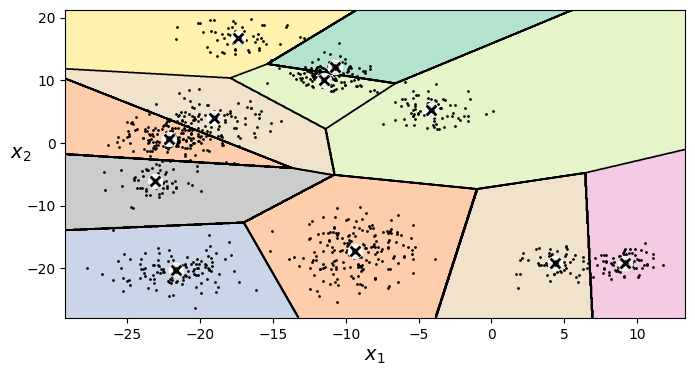

In [144]:
k = len(blob_centers)
kmeans = KMeans(n_clusters=k, random_state=42)
y_pred = kmeans.fit_predict(X)

plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.show()

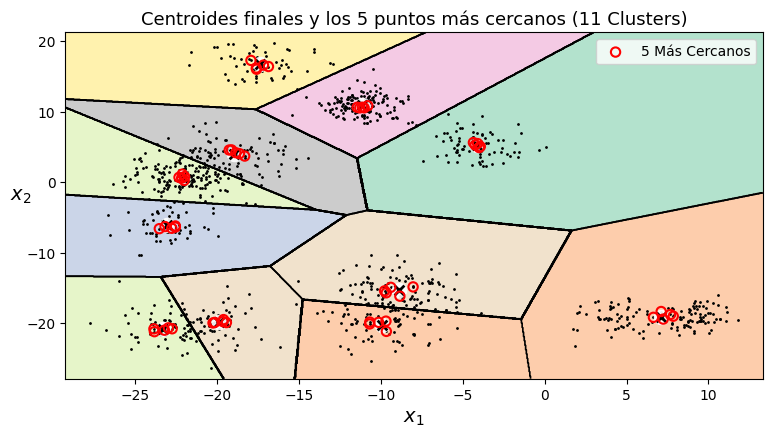

In [145]:
plt.figure(figsize=(9, 4.5))
plot_decision_boundaries(kmeans_final, X)

todos_los_5 = [idx for grupo in cinco_mas_cercanos.values() for idx in grupo]
plt.scatter(X[todos_los_5, 0], X[todos_los_5, 1],
            facecolors='none', edgecolors='red', s=45, linewidths=1.5, zorder=12, label='5 Más Cercanos')

plt.title(f"Centroides finales y los 5 puntos más cercanos ({k} Clusters)", fontsize=13)
plt.legend(loc='upper right')
plt.show()

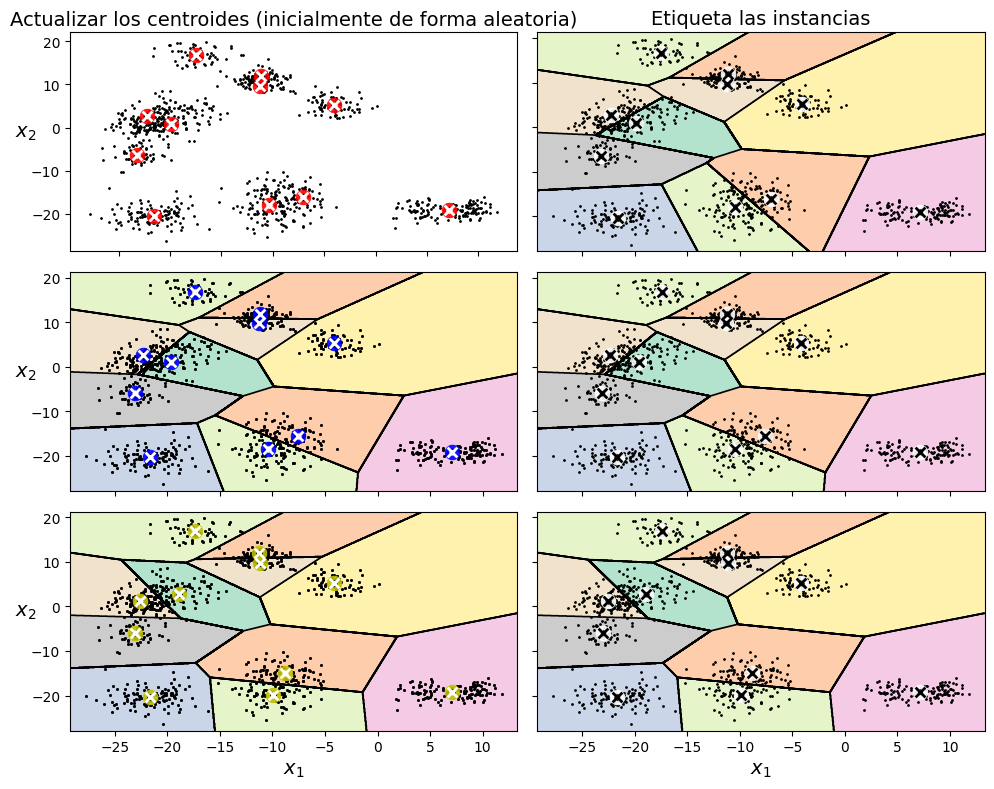

In [160]:
plt.figure(figsize=(10, 8))

plt.subplot(321)
plot_data(X)
plot_centroids(kmeans_iter1.cluster_centers_, circle_color='r', cross_color='w')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Actualizar los centroides (inicialmente de forma aleatoria)", fontsize=14)

plt.subplot(322)
plot_decision_boundaries(kmeans_iter1, X, show_xlabels=False, show_ylabels=False)
plt.title("Etiqueta las instancias", fontsize=14)

plt.subplot(323)
plot_decision_boundaries(kmeans_iter2, X, show_centroids=False, show_xlabels=False)
plot_data(X)
plot_centroids(kmeans_iter2.cluster_centers_, circle_color='b', cross_color='w')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)

plt.subplot(324)
plot_decision_boundaries(kmeans_iter2, X, show_xlabels=False, show_ylabels=False)

plt.subplot(325)
plot_decision_boundaries(kmeans_iter3, X, show_centroids=False)
plot_data(X)
plot_centroids(kmeans_iter3.cluster_centers_, circle_color='y', cross_color='w')
plt.ylabel("$x_2$", fontsize=14, rotation=0)

plt.subplot(326)
plot_decision_boundaries(kmeans_iter3, X, show_ylabels=False)

plt.tight_layout()
plt.show()

**Punto 2**

In [ ]:
from sklearn.cluster import KMeans
import random

In [147]:
n_centers_3d = random.randint(1, 20)

blob_centers_3d = []
while len(blob_centers_3d) < n_centers_3d:

  candidate = np.random.uniform(-25, 25, size=3)
  if all(np.linalg.norm(candidate - center) > 4 for center in blob_centers_3d):
    blob_centers_3d.append(candidate)

blob_centers_3d = np.array(blob_centers_3d)

blob_std_3d = np.random.uniform(1, 2.5, size=n_centers_3d)

puntos_por_centroide_3d = [
    random.randint(50, 150) for _ in range(n_centers_3d)
]

X_3d, y_3d = make_blobs(
    n_samples=puntos_por_centroide_3d,
    centers=blob_centers_3d,
    cluster_std=blob_std_3d,
    random_state=42,
)

print(f"Se generaron {n_centers_3d} centroides en 3D")
print("Coordenadas de los centroides iniciales/reales (3D):")
print(blob_centers_3d)

Se generaron 11 centroides en 3D
Coordenadas de los centroides iniciales/reales (3D):
[[ 24.82701221  15.96643243  -8.6104399 ]
 [-15.40867848  15.88213078  -4.88806068]
 [  4.24848329 -22.87476231  15.31914535]
 [-14.8870493   13.17569168   8.01533972]
 [ -4.37520931   1.67563386   1.88152478]
 [-13.73755167 -18.53780353  15.50418916]
 [  9.50456252   6.06806046 -11.08204645]
 [ -4.89470469 -17.63671388  12.72072812]
 [-24.24691328 -24.85600259   1.04792512]
 [ 21.60373157 -10.96637839   5.13307655]
 [ 12.24270347   5.79022343  -5.85144954]]


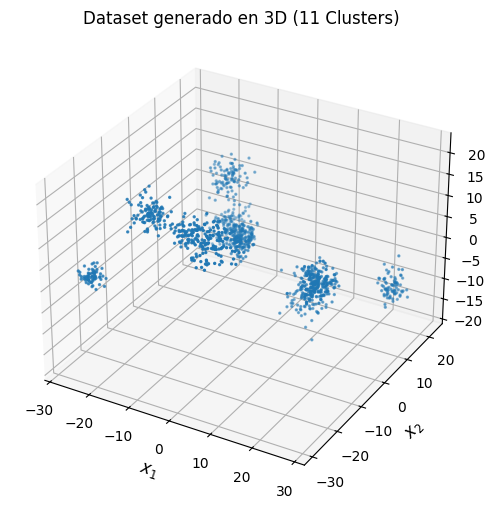

In [148]:
def plot_clusters_3d(X, y=None):
  fig = plt.figure(figsize=(8, 6))
  ax = fig.add_subplot(111, projection="3d")
  ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=y, s=2)
  ax.set_xlabel("$x_1$", fontsize=12)
  ax.set_ylabel("$x_2$", fontsize=12)
  ax.set_zlabel("$x_3$", fontsize=12)
  plt.title(f"Dataset generado en 3D ({n_centers_3d} Clusters)")
  plt.show()


plot_clusters_3d(X_3d)

In [164]:
k_3d = n_centers_3d

kmeans_iter1_3d = KMeans(n_clusters=k_3d,init="k-means++",n_init=1,algorithm="lloyd",max_iter=1,random_state=1,)
kmeans_iter2_3d = KMeans(n_clusters=k_3d,init="k-means++",n_init=1,algorithm="lloyd",max_iter=2,random_state=1,)
kmeans_iter3_3d = KMeans(n_clusters=k_3d,init="k-means++",n_init=1,algorithm="lloyd",max_iter=5,random_state=1,)

kmeans_iter1_3d.fit(X_3d)
kmeans_iter2_3d.fit(X_3d)
kmeans_iter3_3d.fit(X_3d)

kmeans_final_3d = KMeans(
    n_clusters=k_3d, init="k-means++", n_init=10, random_state=42
)
y_pred_3d = kmeans_final_3d.fit_predict(X_3d)
print(f"RESULTADOS FINALES DE K-MEANS 3D ({k_3d} CLUSTERS) ")
print("Ubicación final de los centroides:")
print(kmeans_final_3d.cluster_centers_)


RESULTADOS FINALES DE K-MEANS 3D (11 CLUSTERS) 
Ubicación final de los centroides:
[[  9.47096503   6.09423873 -10.98172559]
 [-13.51650707 -18.53402872  15.45317206]
 [-14.54709075  13.02714538   8.26407656]
 [ 21.57453388 -11.184302     5.20889219]
 [-24.37357122 -24.65924796   1.21130527]
 [ -4.11712349   1.7606062    1.89594372]
 [  4.32818182 -22.60163656  15.52454275]
 [ 24.94453006  15.77901912  -8.57189919]
 [-15.20483487  15.53215044  -4.65233768]
 [ 12.30633788   5.60708749  -5.44418898]
 [ -4.9780629  -17.5566894   12.85403481]]


In [150]:
cinco_mas_cercanos_3d = {}

for i in range(k_3d):
  puntos_idx = np.where(y_pred_3d == i)[0]
  puntos_cluster = X_3d[puntos_idx]
  n_puntos = len(puntos_cluster)

  centroide = kmeans_final_3d.cluster_centers_[i]
  distancias = np.linalg.norm(puntos_cluster - centroide, axis=1)

  idx_top5 = puntos_idx[np.argsort(distancias)[: min(5, n_puntos)]]
  cinco_mas_cercanos_3d[i] = idx_top5

  print(f"\nCentroide {i}")
  print(f"  Coordenadas: {np.round(centroide, 3)}")
  print(f"  Número de puntos asignados: {n_puntos}")
  print(f"  5 puntos más cercanos (índices): {idx_top5}")
  for idx in idx_top5:
    dist = np.linalg.norm(X_3d[idx] - centroide)
    print(f"    Punto {idx}: {np.round(X_3d[idx], 3)} | Distancia: {dist:.4f}")

RESULTADOS FINALES DE K-MEANS 3D (11 CLUSTERS) 
Ubicación final de los centroides:
[[  9.47096503   6.09423873 -10.98172559]
 [-13.51650707 -18.53402872  15.45317206]
 [-14.54709075  13.02714538   8.26407656]
 [ 21.57453388 -11.184302     5.20889219]
 [-24.37357122 -24.65924796   1.21130527]
 [ -4.11712349   1.7606062    1.89594372]
 [  4.32818182 -22.60163656  15.52454275]
 [ 24.94453006  15.77901912  -8.57189919]
 [-15.20483487  15.53215044  -4.65233768]
 [ 12.30633788   5.60708749  -5.44418898]
 [ -4.9780629  -17.5566894   12.85403481]]

Centroide 0
  Coordenadas: [  9.471   6.094 -10.982]
  Número de puntos asignados: 77
  5 puntos más cercanos (índices): [ 942  777   98  220 1034]
    Punto 942: [  9.505   6.046 -11.861] | Distancia: 0.8808
    Punto 777: [  9.916   6.647 -11.612] | Distancia: 0.9494
    Punto 98: [  9.178   6.995 -11.327] | Distancia: 1.0082
    Punto 220: [ 8.436  6.069 -9.655] | Distancia: 1.6834
    Punto 1034: [ 8.871  5.049 -9.685] | Distancia: 1.7705

Centr

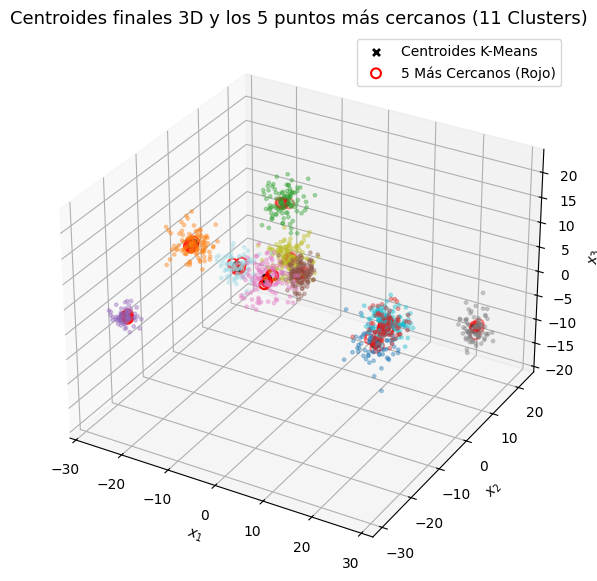

In [151]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], c=y_pred_3d, cmap="tab20", s=6, alpha=0.35
)

centros = kmeans_final_3d.cluster_centers_
ax.scatter(
    centros[:, 0],
    centros[:, 1],
    centros[:, 2],
    marker="o",
    s=40,
    color="w",
    edgecolors="k",
    linewidths=2,
    zorder=10,
)
ax.scatter(
    centros[:, 0],
    centros[:, 1],
    centros[:, 2],
    marker="x",
    s=25,
    color="k",
    linewidths=2,
    zorder=11,
    label="Centroides K-Means",
)

todos_los_5_3d = [
    idx for grupo in cinco_mas_cercanos_3d.values() for idx in grupo
]
ax.scatter(
    X_3d[todos_los_5_3d, 0],
    X_3d[todos_los_5_3d, 1],
    X_3d[todos_los_5_3d, 2],
    facecolors="none",
    edgecolors="red",
    s=50,
    linewidths=1.5,
    zorder=12,
    label="5 Más Cercanos (Rojo)",
)

ax.set_title(
    f"Centroides finales 3D y los 5 puntos más cercanos ({k_3d} Clusters)",
    fontsize=13,
)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")
ax.legend(loc="upper right")
plt.show()

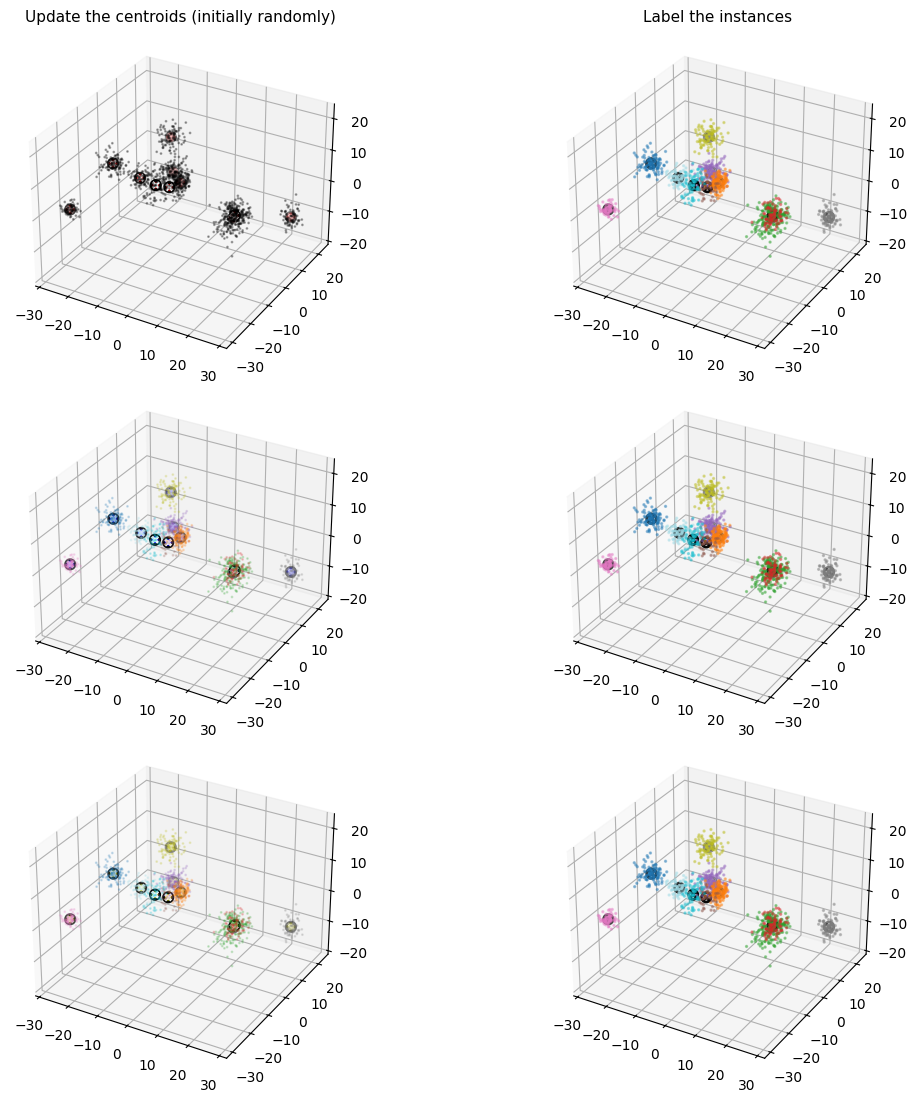

In [152]:
fig = plt.figure(figsize=(13, 11))


def plot_centroids_3d(ax, centroids, circle_color="w", cross_color="k"):
  ax.scatter(
      centroids[:, 0],
      centroids[:, 1],
      centroids[:, 2],
      marker="o",
      s=45,
      color=circle_color,
      edgecolors="k",
      linewidths=2,
      zorder=10,
  )
  ax.scatter(
      centroids[:, 0],
      centroids[:, 1],
      centroids[:, 2],
      marker="x",
      s=20,
      color=cross_color,
      linewidths=2,
      zorder=11,
  )


ax1 = fig.add_subplot(3, 2, 1, projection="3d")
ax1.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], c="k", s=1, alpha=0.3)
plot_centroids_3d(
    ax1, kmeans_iter1_3d.cluster_centers_, circle_color="r", cross_color="w"
)
ax1.set_title("Update the centroids (initially randomly)", fontsize=11)

ax2 = fig.add_subplot(3, 2, 2, projection="3d")
ax2.scatter(
    X_3d[:, 0],
    X_3d[:, 1],
    X_3d[:, 2],
    c=kmeans_iter1_3d.labels_,
    cmap="tab20",
    s=2,
    alpha=0.4,
)
plot_centroids_3d(ax2, kmeans_iter1_3d.cluster_centers_)
ax2.set_title("Label the instances", fontsize=11)

ax3 = fig.add_subplot(3, 2, 3, projection="3d")
ax3.scatter(
    X_3d[:, 0],
    X_3d[:, 1],
    X_3d[:, 2],
    c=kmeans_iter1_3d.labels_,
    cmap="tab20",
    s=1,
    alpha=0.2,
)
plot_centroids_3d(
    ax3, kmeans_iter2_3d.cluster_centers_, circle_color="b", cross_color="w"
)

ax4 = fig.add_subplot(3, 2, 4, projection="3d")
ax4.scatter(
    X_3d[:, 0],
    X_3d[:, 1],
    X_3d[:, 2],
    c=kmeans_iter2_3d.labels_,
    cmap="tab20",
    s=2,
    alpha=0.4,
)
plot_centroids_3d(ax4, kmeans_iter2_3d.cluster_centers_)

ax5 = fig.add_subplot(3, 2, 5, projection="3d")
ax5.scatter(
    X_3d[:, 0],
    X_3d[:, 1],
    X_3d[:, 2],
    c=kmeans_iter2_3d.labels_,
    cmap="tab20",
    s=1,
    alpha=0.2,
)
plot_centroids_3d(
    ax5, kmeans_iter3_3d.cluster_centers_, circle_color="y", cross_color="w"
)

ax6 = fig.add_subplot(3, 2, 6, projection="3d")
ax6.scatter(
    X_3d[:, 0],
    X_3d[:, 1],
    X_3d[:, 2],
    c=kmeans_iter3_3d.labels_,
    cmap="tab20",
    s=2,
    alpha=0.4,
)
plot_centroids_3d(ax6, kmeans_iter3_3d.cluster_centers_)

plt.tight_layout()
plt.show()

**Punto 3**

In [165]:
import os
import urllib.request
import numpy as np
from sklearn.model_selection import train_test_split

classes = ['airplane', 'apple', 'bicycle', 'cat', 'car', 'star']
base_url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"

os.makedirs("quickdraw_data", exist_ok=True)

print("Iniciando descarga de Quick, Draw")
for c in classes:
    c_url = c.replace(' ', '%20')
    file_path = f"quickdraw_data/{c}.npy"
    if not os.path.exists(file_path):
        urllib.request.urlretrieve(f"{base_url}{c_url}.npy", file_path)

print("Descarga completada\n")

samples_per_class = 2000
X_list = []
y_oracle_list = []

for idx, c in enumerate(classes):
    data = np.load(f"quickdraw_data/{c}.npy")
    data = data[:samples_per_class]
    X_list.append(data)
    y_oracle_list.append(np.full(len(data), idx))

X_raw = np.concatenate(X_list, axis=0).astype(np.float32) / 255.0
y_oracle = np.concatenate(y_oracle_list, axis=0)


X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_oracle, test_size=0.20, random_state=42, stratify=y_oracle
)

print(f"\nConjunto de entrenamiento: {X_train.shape[0]} muestras")
print(f"Conjunto de prueba: {X_test.shape[0]} muestras")

Iniciando descarga de Quick, Draw
Descarga completada


Conjunto de entrenamiento: 9600 muestras
Conjunto de prueba: 2400 muestras


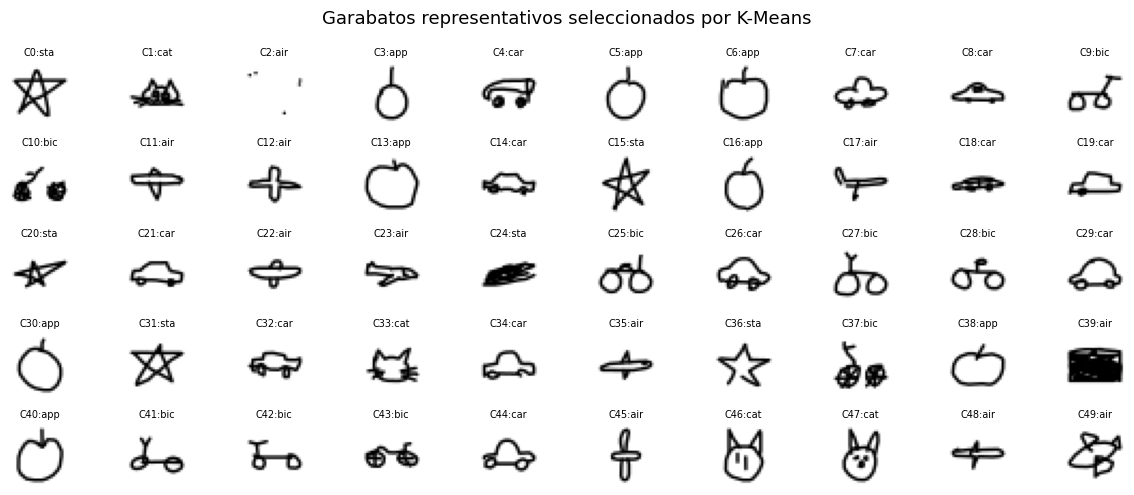

In [154]:
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

k = 60
kmeans = MiniBatchKMeans(n_clusters=k, random_state=42, batch_size=512)
X_dist = kmeans.fit_transform(X_train)

rep_indices = np.argmin(X_dist, axis=0)
X_representative = X_train[rep_indices]
y_representative = y_train[rep_indices]

plt.figure(figsize=(12, 5))
for i in range(min(50, k)):
    plt.subplot(5, 10, i + 1)
    plt.imshow(X_representative[i].reshape(28, 28), cmap="gray_r")
    plt.title(f"C{i}:{classes[y_representative[i]][:3]}", fontsize=7)
    plt.axis("off")
plt.suptitle("Garabatos representativos seleccionados por K-Means", fontsize=13)
plt.tight_layout()
plt.show()


In [155]:
clf_base = LogisticRegression(max_iter=1000, random_state=42)
clf_base.fit(X_representative, y_representative)
acc_base = accuracy_score(y_test, clf_base.predict(X_test))
print(f"-> Accuracy Modelo Base (solo {k} muestras etiquetadas): {acc_base * 100:.2f}%\n")

cluster_labels = kmeans.labels_
distances_to_centroid = X_dist[np.arange(len(X_train)), cluster_labels]
percentile_threshold = 20
propagated_idx = []

for c in range(k):
    in_cluster = (cluster_labels == c)
    dists_in_c = distances_to_centroid[in_cluster]
    if len(dists_in_c) == 0:
        continue
    cutoff = np.percentile(dists_in_c, percentile_threshold)
    selected = np.where(in_cluster & (distances_to_centroid <= cutoff))[0]
    propagated_idx.extend(selected)

propagated_idx = np.array(propagated_idx)
X_train_semi = X_train[propagated_idx]
y_train_semi = y_representative[cluster_labels[propagated_idx]]

clf_semi = LogisticRegression(max_iter=1000, random_state=42)
clf_semi.fit(X_train_semi, y_train_semi)
acc_semi = accuracy_score(y_test, clf_semi.predict(X_test))

print(f"-> Accuracy Semisupervisado (Propagación al {percentile_threshold}%): {acc_semi * 100:.2f}%")
print(f"-> Muestras aprovechadas: {len(X_train_semi)} de {len(X_train)}\n")


-> Accuracy Modelo Base (solo 60 muestras etiquetadas): 60.88%

-> Accuracy Semisupervisado (Propagación al 20%): 63.62%
-> Muestras aprovechadas: 1943 de 9600



In [156]:
n_rounds = 5
step = 30

active_idx = list(rep_indices)
random_idx = list(rep_indices)

acc_act_hist = [acc_base]
acc_rnd_hist = [acc_base]
sample_counts = [len(active_idx)]

clf_active = LogisticRegression(max_iter=1000, random_state=42)
clf_random = LogisticRegression(max_iter=1000, random_state=42)

for r in range(1, n_rounds + 1):
    clf_active.fit(X_train[active_idx], y_train[active_idx])
    clf_random.fit(X_train[random_idx], y_train[random_idx])

    unlabeled_act = np.setdiff1d(np.arange(len(X_train)), active_idx)
    probs = clf_active.predict_proba(X_train[unlabeled_act])
    sorted_probs = np.sort(probs, axis=1)
    margins = sorted_probs[:, -1] - sorted_probs[:, -2]
    uncertain_selected = unlabeled_act[np.argsort(margins)[:step]]

    unlabeled_rnd = np.setdiff1d(np.arange(len(X_train)), random_idx)
    rand_selected = np.random.choice(unlabeled_rnd, size=step, replace=False)

    active_idx.extend(uncertain_selected)
    random_idx.extend(rand_selected)

    clf_active.fit(X_train[active_idx], y_train[active_idx])
    clf_random.fit(X_train[random_idx], y_train[random_idx])

    acc_act = accuracy_score(y_test, clf_active.predict(X_test))
    acc_rnd = accuracy_score(y_test, clf_random.predict(X_test))

    acc_act_hist.append(acc_act)
    acc_rnd_hist.append(acc_rnd)
    sample_counts.append(len(active_idx))

    print(f"Ronda {r}/{n_rounds} | Muestras: {len(active_idx)} | Acc Activo: {acc_act*100:.2f}% | Acc Aleatorio: {acc_rnd*100:.2f}%")


Ronda 1/5 | Muestras: 90 | Acc Activo: 65.21% | Acc Aleatorio: 62.54%
Ronda 2/5 | Muestras: 120 | Acc Activo: 66.92% | Acc Aleatorio: 63.88%
Ronda 3/5 | Muestras: 150 | Acc Activo: 68.54% | Acc Aleatorio: 64.88%
Ronda 4/5 | Muestras: 180 | Acc Activo: 69.88% | Acc Aleatorio: 67.25%
Ronda 5/5 | Muestras: 210 | Acc Activo: 69.88% | Acc Aleatorio: 67.42%


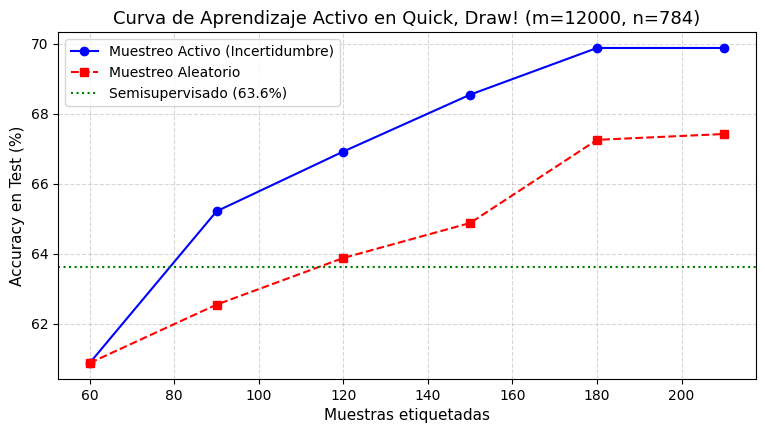

In [158]:
plt.figure(figsize=(9, 4.5))
plt.plot(sample_counts, np.array(acc_act_hist) * 100, "b-o", label="Muestreo Activo (Incertidumbre)")
plt.plot(sample_counts, np.array(acc_rnd_hist) * 100, "r--s", label="Muestreo Aleatorio")
plt.axhline(y=acc_semi * 100, color="g", linestyle=":", label=f"Semisupervisado ({acc_semi*100:.1f}%)")
plt.xlabel("Muestras etiquetadas", fontsize=11)
plt.ylabel("Accuracy en Test (%)", fontsize=11)
plt.title(f"Curva de Aprendizaje Activo en Quick, Draw! (m={m}, n={n})", fontsize=13)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="best")
plt.show()